<b>Importando bibiliotecas</b>

In [2]:
import numpy as np
import pandas as pd
from sklearn import tree
from six import StringIO
import pydotplus
from IPython.display import Image
from sklearn.model_selection import train_test_split

<b>Carregando dados</b>


In [3]:
col_names = ['prognosis', 'fatigue', 'vomiting', 'high_fever', 'loss_of_appetite', 'nausea', 'headache', 'abdominal_pain', 'yellowish_skin', 'yellowing_of_eyes', 'chills', 'skin_rash']
data = pd.read_csv('data/Sintomas_menor.csv',skiprows=1,header=None,names = col_names)

In [4]:
# Dados de exemplo
X = data.iloc[:,1:]
Y = data.iloc[:,0]
X_train,X_test,Y_train,Y_test = train_test_split(X,Y,test_size=.2,random_state=41)

<b>Treinando o modelo</b>

In [5]:
# Criar o classificador de árvore de decisão
clf = tree.DecisionTreeClassifier()

# Treinar o classificador usando os dados
clf = clf.fit(X_train, Y_train)

<b>Gerando Caminho da Arvore</b>

In [6]:
# Gerar o código da àrvore
with open('treecode.txt','w+') as file:
    file.write(tree.export_text(clf))

<b>Gerando gráfico</b>


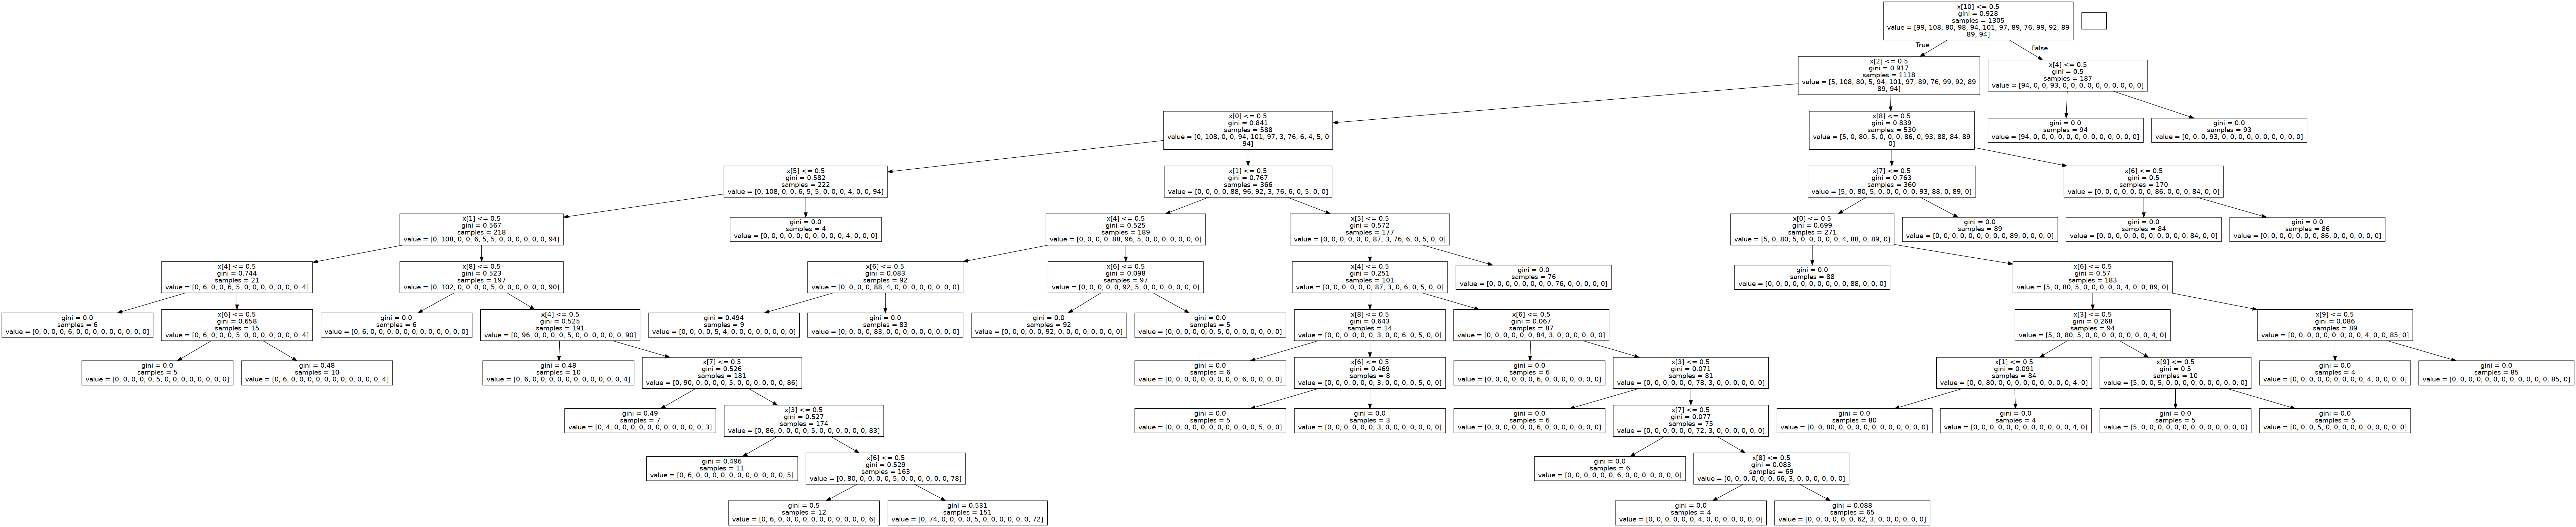

In [7]:
# Gerar a representação gráfica da árvore
dot_data = StringIO()
tree.export_graphviz(clf, out_file=dot_data)
graph = pydotplus.graph_from_dot_data(dot_data.getvalue())

# Salvar a imagem da árvore em um arquivo
graph.write_png('arvore_decisao.png')

# Exibir a imagem da árvore
Image(graph.create_png())